# 10. Solvent: The Environment Matters

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/10-Solvent/101-Solvent.ipynb)
:::

Every calculation demonstrated so far had been performed in **gas phase**. We are modelling a single molecule in a vacuum. That is not the real world. Reactions occur at air pressure, at somewhat sane temperatures (generally less than 200 &deg;C) and in **solvent**.

We will **set up** a transition state for an *S<sub>N</sub>2* reaction, **optimize** it in **gas phase**, follow the reaction path downhill, and then ask how a polar **solvent**, water, changes the energy along that path.

## Learning Goals

This exercise will hopefully accomplish the following goals while learning new skills:
-	We will add a **solvent model** (PCM, water) to a *Psi4* calculation with a few options.
-	We will **build** a *D<sub>3h</sub>* transition state from three symmetry-unique positions and let **symmetry** hold it on the saddle point.
-	We will find the **imaginary vibration** in gas phase and in water.
-	We will learn why derivatives (gradients and Hessians) are **hard** with a continuum solvent model in *Psi4*, and what we can do instead.
-	We will follow the **intrinsic reaction coordinate** (IRC) in both directions in gas phase, **make a movie** of the reaction, and calculate the energy in **water** at every point along the path.
-	We will compare the ends of each IRC with the **ground state** of methyl chloride.

```{note}
This chapter has three parts. This notebook runs all the calculations. The [second notebook](102-IRCData.ipynb) cleans and collates the IRC data with *pandas*, and the [third notebook](103-IRCPlots.ipynb) plots it.
```

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
# ddX (the solvent model, package pyddx) is a separate conda package.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4 pyddx
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")
print("done")

done


## Setting Up the Notebook

As in every chapter, the hidden **first code cell** imports *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot style sheet. You will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*.

The solvent model that we will use comes from a separate library called *ddX*. It is **not** installed along with *Psi4*. It is a **conda package** of its own, called `pyddx`, and I had to install it before this notebook would run. Open a terminal, activate your `psi4` environment and type `conda install -c conda-forge pyddx`, then restart the notebook. (If you forget, the first calculation in water will stop with an error saying that *ddX* is not available.)

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* (and *ddX*) for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* and *ddX* (`pyddx`) with *conda*, install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

```{warning}
This notebook is **slow**. The gas phase calculations take a few minutes. The **Hessian in water** is the slowest cell, because *Psi4* cannot calculate the slope of the energy (the gradient) directly when the solvent model is switched on. It has to work it out from many energies at slightly different geometries. More on that below. The water calculations also use a lot of **memory**. When the notebook has finished, restart the kernel (`Kernel` &rarr; `Restart Kernel`) to give it back.
```

Next, we tell *Psi4* how much of the computer it may use.

In [2]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk"})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `psi4.set_options({"scf_type": "pk"})` | Calculate the electron repulsion integrals **exactly** rather than with density fitting, as *GAMESS* does. Our molecule is tiny so the cost is trivial. |

### Some Helpful Tools

We will reuse some **small functions** from earlier chapters and add four new ones. `new_output()` starts a new output file for each job (more on it in the table below). `c1_copy()` makes a copy of a molecule with **symmetry switched off**. We will need it because the solvent model cannot use symmetry. `read_irc()` reads the trajectory file that *Psi4* writes during an IRC calculation (we met it in the [Diels-Alder chapter](../09-DielsAlder/091-DielsAlder.ipynb)), and `show_movie()` plays a list of structures as an animation. Run the cell below once.

In [3]:
#| class: scroll-input
import logging

def new_output(filename):
    logger = logging.getLogger("psi4")
    for handler in logger.handlers[:]:
        if isinstance(handler, logging.FileHandler):
            handler.close()
            logger.removeHandler(handler)
    psi4.set_output_file(filename, False)

def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_vibration(wfn, mode=0):
    vib = wfn.frequency_analysis
    vibrations = [i for i, kind in enumerate(vib["TRV"].data) if kind == "V"]
    vector = vib["x"].data[:, vibrations[mode]].reshape(-1, 3)
    mol = wfn.molecule()
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms

    lines = [str(mol.natom()), "normal mode"]
    for i in range(mol.natom()):
        x, y, z = xyz[i]
        dx, dy, dz = vector[i]
        lines.append(f"{mol.symbol(i)} {x:.6f} {y:.6f} {z:.6f} {dx:.6f} {dy:.6f} {dz:.6f}")

    view = py3Dmol.view(width=400, height=300)
    view.addModel("\n".join(lines), "xyz", {"vibrate": {"frames": 10, "amplitude": 1.0}})
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.animate({"loop": "backAndForth"})
    view.zoomTo()
    view.show()

def c1_copy(mol):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    lines = [f"{int(mol.molecular_charge())} {mol.multiplicity()}"]
    for i in range(mol.natom()):
        x, y, z = xyz[i]
        lines.append(f"{mol.symbol(i)} {x:.10f} {y:.10f} {z:.10f}")
    lines.append("symmetry c1")
    lines.append("no_reorient")
    lines.append("no_com")
    return psi4.geometry("\n".join(lines))

def read_irc(filename):
    with open(filename) as f:
        lines = f.readlines()

    frames = []
    i = 0
    while i < len(lines) and lines[i].strip() != "":
        natom = int(lines[i])
        title = lines[i + 1].split()
        atoms = lines[i + 2:i + 2 + natom]
        symbols = [atom.split()[0] for atom in atoms]
        xyz = np.array([[float(v) for v in atom.split()[1:4]] for atom in atoms])
        xyz = xyz * psi4.constants.bohr2angstroms

        text = f"{natom}\n{lines[i + 1].strip()}\n"
        for symbol, (x, y, z) in zip(symbols, xyz):
            text = text + f"{symbol} {x:10.6f} {y:10.6f} {z:10.6f}\n"

        frames.append({"Step": int(float(title[3])),
                       "Energy": float(title[5]),
                       "text": text,
                       "xyz": xyz})
        i = i + 2 + natom
    return frames

def show_movie(frames):
    movie = "".join(frame["text"] for frame in frames)
    view = py3Dmol.view(width=400, height=300)
    view.addModelsAsFrames(movie, "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.animate({"loop": "backAndForth", "interval": 100})
    view.zoomTo()
    view.show()
    return movie

| Function | What it does |
| :---- | :---- |
| `new_output(filename)` | Sends the *Psi4* output to `filename` and the log to a matching `.log` file, after first **detaching** any `.log` file from an earlier job. `psi4.set_output_file()` alone leaves the old log files attached, and every later job then writes its log into all of them. |
| `show_molecule(mol)` | Draws a *Psi4* molecule in a 3-D viewer that you can spin with the mouse. |
| `bond_length(mol, i, j)` | Distance between atoms `i` and `j` in &Aring;ngstroms. Remember that *Python* counts atoms from **0**. |
| `bond_angle(mol, i, j, k)` | The angle *i*&ndash;*j*&ndash;*k* in degrees, with atom *j* at the vertex. |
| `search_file(filename, text)` | Prints every line of a file that contains `text`, with its line number. It is our replacement for *grep*. |
| `show_vibration(wfn, mode)` | Animates one **normal mode** of a frequency calculation. Mode 0 is the lowest, and an imaginary mode comes first. |
| `c1_copy(mol)` | Writes out the atoms of a molecule again with `symmetry c1`, `no_reorient` and `no_com` added. The copy has **no symmetry** and *Psi4* will not move or turn it. |
| `read_irc(filename)` | Reads an IRC trajectory file into a list of **frames**. Each frame holds the step number, the energy, the coordinates (converted from Bohr to &Aring;ngstroms) and the frame as *xyz* text. |
| `show_movie(frames)` | Joins the frames into one multi-frame *xyz* text, plays it in *py3Dmol* and returns the text so we can save it. |

## Solvent Models

A charged system will be very high in energy in a **vacuum** but may be perfectly stable in **water**, where dipoles can arrange to oppose the charge and relax the system. Solvent can have many effects. Protic solvents can assist the reaction by interacting **directly** with the reactants. Solvents might serve as an acid or a base **catalyst**, for example. Solvents can form structured **cages** around reactants and affect the outcome of very fast reactions.

But the biggest effect will be **stabilization** of charges by dipole-dipole interactions. There is a lot to think about for solvent effects and so models that adjust the energies of the calculation by including solvent effects can be **quite complex**. We can include the molecules of the solvent in our ***ab initio*** calculations, we could model the solvent using **molecular mechanics** to account for its random motion but still involve its presence when atoms become near enough to the reactant to be included in *ab initio* methods. These methods will be costly.

A common method that is less costly is to treat solvent like an electric field. This is the **continuum model**. The solvent is mathematically modelled as a field that **interacts** with the molecule being modelled. There are many options and we will be using the popular PCM (polarizable continuum model). The molecule sits in a **cavity**, a bubble built from a sphere around each atom. The surface of the cavity is cut into many small tiles (*tesserae*), and the program places a **charge** on each tile that represents the polarized solvent. The charges change the energy and the orbitals of the molecule, and the molecule changes the charges, so they are solved together in each cycle of the SCF.

### Adding Solvent in *Psi4*

In *GAMESS*, the PCM model was included by adding a `$PCM` group to the input file and declaring the `SOLVNT` parameter.

```text
 $PCM SOLVNT = WATER $END
```

*Psi4* can use two different libraries for continuum solvent models, *PCMSolver* and *ddX*. We will use *ddX*, and the box after the next cell explains why. We switch it on and describe the solvent and the cavity with a few options.

In [4]:
def use_water():
    psi4.set_options({"ddx": True,
                      "ddx_model": "cosmo",
                      "ddx_solvent": "water",
                      "ddx_radii_set": "bondi",
                      "ddx_radii_scaling": 1.2,
                      "ddx_solute_radial_points": 99,
                      "ddx_solute_spherical_points": 590,
                      "dft_radial_points": 99,
                      "dft_spherical_points": 590})

| Line | Notes |
| :---- | :---- |
| `def use_water():` | A small function that **switches the solvent on**. We will call it before every calculation in water. |
| `"ddx": True` | Use a solvent model from the *ddX* library. |
| `"ddx_model": "cosmo"` | The **conductor-like** screening model (COSMO). The solvent is first treated as a perfect conductor and the charges are then scaled down for the real dielectric constant. This is the same idea as C-PCM, which, according to the *GAMESS* documentation, is the *GAMESS* default (`IEF=-10`) and is "normally a better choice than IEF-PCM". |
| `"ddx_solvent": "water"` | Looks up the dielectric constant of water. Other names include `methanol`, `benzene`, `cyclohexane` and `dimethylsulfoxide`. |
| `"ddx_solute_radial_points": 99` and `"ddx_solute_spherical_points": 590` | *ddX* works out how the molecule's electrons interact with the solvent on a grid of points around each atom: 99 points along each radius and 590 points on each sphere, instead of the default 35 and 110. See the third box below for why. |
| `"dft_radial_points": 99` and `"dft_spherical_points": 590` | A finer grid for the B3LYP part of the calculation too (the default is 75 and 302). |
| `"ddx_radii_set": "bondi"` and `"ddx_radii_scaling": 1.2` | Each atom's sphere is its **van der Waals radius** (Bondi's table) multiplied by 1.2. *GAMESS* also uses van der Waals radii scaled by 1.2 by default (`RADII=VANDW`, `ALPHA=1.2` in `$PCMCAV`), but its table is not exactly the same, so the cavities will be similar rather than identical. |

There are two things in the *Psi4* manual that we must keep in mind.

```{warning}
1. *ddX* **cannot use point group symmetry**. Every calculation in water must be run in *C<sub>1</sub>*. That is what our `c1_copy()` function is for.
2. **Analytic gradients and Hessians are not available** with *ddX* (or with *PCMSolver*). We must ask *Psi4* to calculate them by **finite differences** with `dertype="energy"` (see the second box below): it moves each atom a tiny bit in each direction, calculates the energy each time, and works out the slopes from the differences. For our six atoms in *C<sub>1</sub>* that is about 25 energies for every gradient and well over a hundred for every Hessian. This is why the water calculations are slow.
```

```{admonition} What went wrong the first time
The first version of this notebook used *Psi4*'s other solvent library, *PCMSolver*, with C-PCM and the *GePol* cavity. The gas phase calculations were fine, and so was a single energy in water. Everything that needed **derivatives** in water went wrong.

- The Hessian at the gas phase transition state gave **three** imaginary frequencies (1943i, 511i and 339i cm<sup>&minus;1</sup>) where the gas phase had one (211i). The transition state search also found three in its own Hessian.
- The Hessian at the start of the IRC was nonsense, with a "vibration" at 3880 cm<sup>&minus;1</sup>, faster than any C&ndash;H stretch.
- The IRC spent 53 minutes on its **first point**. It took 50 small optimization steps, the energy jumped up and down by as much as 0.00045 Hartree, and the largest force swung between 0.001 and 0.4 from one step to the next. After about 4000 energy calculations the computer ran out of memory and the notebook's kernel died.

**Why?** A finite difference divides a tiny change in energy by a tiny move (0.005 Bohr). That only works if the energy changes **smoothly** as the atoms move. *PCMSolver* builds the surface of the cavity from small flat **tiles**. When an atom moves, tiles can appear, disappear or change shape, and the energy takes a tiny **jump**. One energy does not care, but a slope calculated across a jump is garbage. It is like measuring the slope of a staircase with a ruler shorter than one step: you get either zero or a cliff.

**Why *ddX* might fix it.** *ddX* builds the cavity differently. Each atom's sphere carries a fixed grid of points that moves with the atom. Where two spheres overlap, the points inside the neighbouring sphere are not cut off suddenly. They are faded out with a smooth **switching function** (controlled by the `ddx_eta` option, which we leave at its default). So the energy should change smoothly as the atoms move, and the finite differences should make sense. The test is the water Hessian below: we expect **one** imaginary frequency, like the gas phase. Switching libraries also needed one more package, `pyddx`.
```

```{admonition} What went wrong the second time
After switching to *ddX*, I ran the notebook again. It stopped after about a minute, in the transition state search in water: "Could not converge geometry optimization in 50 iterations".

- *The problem.* The Hessian in water now had **four** imaginary frequencies (686i, 505i, 237i and 214i cm<sup>&minus;1</sup>). The transition state search wandered for 50 steps. The largest force jumped between 0.007 and 0.37 although the atoms moved by less than 0.001 Bohr per step, and the energy crept **up** by about 1.7 kJ/mol.
- *The clue.* It was **fast**. The Hessian needed only 31 displaced structures, and the output said `gradient() will perform analytic gradient computation`. *Psi4* was not building the gradients from energies at all.
- *Why it happened.* I looked in the *Psi4* source code. *Psi4* has a special rule that switches to finite differences when *PCMSolver* is on ("PCM analytic gradients are not implemented yet, re-routing to finite differences"). There is **no such rule for *ddX***. So *Psi4* ran its ordinary B3LYP gradient code, which knows nothing about the solvent. The forces it returned left out the push and pull of the water, so they did not belong to the energy that we were calculating. An optimizer steering with the wrong forces cannot find the top of the pass, and a Hessian built from the wrong gradients is meaningless. The manual does say that analytic gradients are not available with *ddX*. It just doesn't stop you from asking for them.
- *The fix and why it might work.* We add `dertype="energy"` to every calculation in water that needs a gradient or a Hessian (at that time `psi4.frequency()`, the transition state search, the water IRCs and the methyl chloride optimization; in the final version of this notebook only the Hessian in water is left). This tells *Psi4* to build them from **energies** only, and the energies **do** include the solvent. The result should be gradients and Hessians that belong to the solvated energy.
- *What I expect.* The water calculations will be slow again (about 25 energies for every gradient), although each *ddX* energy takes only a fraction of a second. This is also the first real test of *ddX*'s smooth cavity: if it works, the water Hessian should show **one** imaginary frequency, like the gas phase. If it still shows several, the solvent energies themselves are too noisy, and we will need another plan.
```

```{admonition} What went wrong the third time
With `dertype="energy"` in place, the Hessian in water was built from 241 energies. It now had **one** imaginary frequency that looked right: 341i cm<sup>&minus;1</sup>, and `show_vibration()` showed the carbon flipping between the two chlorides. But there were three more, at 22528i, 17468i and 14736i cm<sup>&minus;1</sup>. Nothing in this molecule vibrates that fast. They are artifacts.

- *The problem.* Of the 241 energies, 62 were about 0.00029 Hartree (0.75 kJ/mol) **lower** than they should be. They were not scattered at random: they fell on one of two levels, as if a switch had flipped. The jump was in the solvent part of the energy, which was either &minus;0.092966 or &minus;0.093257 Hartree and nothing in between. A jump of 0.0003 Hartree across a move of 0.005 Bohr ruins a slope: a gradient could be wrong by up to 0.03 Hartree/Bohr, more than the real forces that the optimizer follows.
- *Why it happened.* *ddX* calculates the interaction between the electrons and the solvent on a numerical **grid** of points around each atom, built by *Psi4*'s DFT machinery (a coarse one: 35 &times; 110 points per atom). *Psi4* turns every grid to a "standard orientation" that depends on how the nuclear charge is spread out. Our molecule is a **symmetric top** (*D<sub>3h</sub>* at the transition state, *C<sub>3v</sub>* along the whole path): about the Cl&ndash;C&ndash;Cl axis, no direction is special, so the choice of grid orientation around that axis is arbitrary. *Psi4* only treats the molecule as a symmetric top if two of its charge moments agree to 10<sup>&minus;10</sup>. A nudge of 0.005 Bohr breaks that tie, and the grid can swing round the axis to a quite different angle. On a coarse grid, a rotated grid gives a slightly different answer. In gas phase the same thing happens, but there the gradients come from exact formulas, not from differences between energies, so it does no harm.
- *The fix and why it might work.* There is no option to stop *Psi4* turning the grid. Instead we make the grids much **finer** (99 &times; 590 points for both *ddX* and B3LYP). On a fine grid, the integral hardly depends on how the grid is turned, so the jumps should shrink, hopefully far below the energy changes that the finite differences measure.
- *What I expect.* Each energy will take several times longer. The test is the Hessian in water: it should now have **one** imaginary frequency near 340i cm<sup>&minus;1</sup> and no impossible ones. The cell after the Hessian plots all of the displaced energies so that we can see whether the two levels are gone. If the jumps remain, we will run the IRC in gas phase and calculate single point energies in water along it, which needs no derivatives in water at all.
```

## Setting Up the IRC

Symmetry makes life easy. If we consider chloride **reacting** with methyl chloride in an *S<sub>N</sub>2* manner, we will have a *D<sub>3h</sub>* structure at the transition state. I will set it up using my understanding of the **nature** of the *D<sub>3h</sub>* point group.

```{figure} ../../images/Solvent_1.png
---
width: 450px
name: fig10_1
---
*A symmetrical S<sub>N</sub>2 reaction.*
```

There will be only **three** unique atoms. The carbon will be at the **origin** and the chloride will be on the *z*-axis. It will be **reflected** down to the other side along the *z*-axis by the symmetry to give the second chloride. The unique C&ndash;H bond will be **along** the *x*-axis and the two other hydrogens will be **positioned** by symmetry, rotated by 120&deg; within the *xy* *&sigma;<sub>h</sub>* plane.

```{figure} ../../images/Solvent_2.png
---
width: 450px
name: fig10_2
---
*The coordinate system for the D<sub>3h</sub> transition state.*
```

I know that C&ndash;H bonds are generally about 1 &Aring; and a typical C&ndash;Cl bond is 1.7 &Aring; so I chose 2 &Aring; since the bonds should be breaking and forming. Nobody knows the true values, but some people think that they can be calculated. The whole system will have a **charge** of &minus;1.

In *GAMESS* I gave the three unique atoms and the point group `DNH 3`, and *GAMESS* generated the rest. *Psi4* wants **all** the atoms, so we will let *Python* do the generating, as we did for benzene. I will list the atoms in the same order that *GAMESS* used: the two chlorides, the carbon, then the three hydrogens.

In [5]:
r_CCl = 2.0      # starting C-Cl distance (Angstrom)
r_CH = 1.0       # starting C-H distance (Angstrom)

lines = ["-1 1"]
lines.append(f"Cl 0.0 0.0 {-r_CCl}")
lines.append(f"Cl 0.0 0.0 {r_CCl}")
lines.append("C 0.0 0.0 0.0")
for angle in [0, 120, 240]:
    theta = np.radians(angle)
    lines.append(f"H {r_CH * np.cos(theta):.6f} {r_CH * np.sin(theta):.6f} 0.0")

print("\n".join(lines))

sn2 = psi4.geometry("\n".join(lines))
sn2.update_geometry()

print()
print("Full point group:         ", sn2.get_full_point_group())
print("Computational point group:", sn2.schoenflies_symbol())
show_molecule(sn2)

-1 1
Cl 0.0 0.0 -2.0
Cl 0.0 0.0 2.0
C 0.0 0.0 0.0
H 1.000000 0.000000 0.0
H -0.500000 0.866025 0.0
H -0.500000 -0.866025 0.0

Full point group:          C2v
Computational point group: c2v


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `lines = ["-1 1"]` | The first line of the geometry: a **charge** of &minus;1 and a **multiplicity** of 1 (all electrons paired). |
| `f"Cl 0.0 0.0 {-r_CCl}"` | The first chloride, on the &minus;*z* side. The second is its mirror image through the *xy* plane. |
| `for angle in [0, 120, 240]:` | One hydrogen at 0&deg;, then two more rotated by 120&deg; and 240&deg; about the *z*-axis. This is the *C<sub>3</sub>* axis doing its job. |
| `np.radians(angle)` | `np.cos()` and `np.sin()` want **radians**, not degrees. |
| `print("\n".join(lines))` | Shows the geometry text that we built, one atom per line. |

The atoms are numbered as in *GAMESS*: Cl1, Cl2, C3, H4, H5, H6. In *Python* the chlorides are atoms **0** and **1**, and the carbon is atom **2**. So the two C&ndash;Cl bonds that we will follow are `bond_length(mol, 0, 2)` and `bond_length(mol, 1, 2)`. These are the same bonds that *GAMESS* called `STRETCH 1 3` and `STRETCH 2 3`.

*Psi4* should report the full point group as *D<sub>3h</sub>* [[full and computational point group from run]]. As always, it calculates in the largest **Abelian** subgroup, here *C<sub>2v</sub>*. *Psi4* may also turn the molecule to put its axes where it likes them, so do not be surprised if the chlorides are no longer on the *z*-axis.

### Level of Theory

Our first calculation will be in **gas phase**. Here is what the *GAMESS* input file asked for, and how we ask *Psi4* for the same thing.

| *GAMESS* | Meaning (from the *GAMESS* documentation) | *Psi4* |
| :---- | :---- | :---- |
| `RUNTYP=OPTIMIZE` | Optimize the geometry. | `psi4.optimize(...)` |
| `DFTTYP=B3LYP` | The B3LYP density functional. | `"b3lyp/..."` in the method text (but see the dropdown below) |
| `SCFTYP=ROHF`, `MULT=1` | Restricted open-shell. With a singlet there are **no** open shells, so this is the same as an ordinary closed-shell calculation. | *Psi4*'s default for a singlet DFT calculation, `reference rks` (restricted Kohn-Sham). |
| `ICHARG=-1` | A charge of &minus;1. | The `-1 1` line at the top of the geometry. |
| `GBASIS=N21 NGAUSS=3` | The 3-21G basis set. No `NDFUNC`, so no *d* functions on chlorine. | `".../3-21g"` |
| `DIRSCF=.TRUE.` | Calculate the integrals as they are needed instead of storing them. The integrals are still exact. | `"scf_type": "pk"` (exact integrals). |
| `OPTTOL=0.0001 NSTEP=40` | Stop when the largest gradient is below 0.0001 Hartree/Bohr, or after 40 steps. | *Psi4*'s default criteria (`g_convergence qchem`) and up to 50 steps (`geom_maxiter`). The criteria are defined differently, so they are not exactly equivalent. |
| `$ZMAT AUTO=.TRUE. DLC=.TRUE.` and `NONVDW` | Generate internal coordinates automatically, so that the bond lengths are printed in the log file, and include the two long C&ndash;Cl "bonds". | *Psi4*'s optimizer always builds its own internal coordinates, and we measure the bond lengths ourselves with `bond_length()`. |

I picked the 3-21G **basis set** (probably a poor choice, but I wanted to finish the calculation quickly).

```{admonition} Which B3LYP?
:class: dropdown
As we saw in the [allyl cation chapter](../06-PiOrbitals/061-PiOrbitals.ipynb), there is more than one B3LYP. *Psi4*'s `b3lyp` uses the VWN1RPA version of the VWN correlation functional. *GAMESS*'s `DFTTYP=B3LYP` uses VWN formula 5, which *Psi4* calls `b3lyp5`. Total energies differ by about 0.1 Hartree, but structures, vibrations and **relative energies** are almost identical. We will use `b3lyp` throughout, and do one `b3lyp5` calculation below to check our transition state against the *GAMESS* book.
```

In [6]:
new_output("sn2_gas_opt.out")

E_ts_gas, hist_ts_gas = psi4.optimize("b3lyp/3-21g", molecule=sn2, return_history=True)

print(f"Final energy: {E_ts_gas:.8f} Hartree")
print("Steps taken: ", len(hist_ts_gas["energy"]))
print("Point group: ", sn2.get_full_point_group())
print()
print(f"C3-Cl1  {bond_length(sn2, 0, 2):.4f} Angstrom")
print(f"C3-Cl2  {bond_length(sn2, 1, 2):.4f} Angstrom")
print(f"C3-H4   {bond_length(sn2, 2, 3):.4f} Angstrom")

Optimizer: Optimization complete!
Final energy: -955.77602209 Hartree
Steps taken:  9
Point group:  C2v

C3-Cl1  2.3829 Angstrom
C3-Cl2  2.3829 Angstrom
C3-H4   1.0736 Angstrom


| Line | Notes |
| :---- | :---- |
| `psi4.optimize("b3lyp/3-21g", ...)` | Optimize the geometry with B3LYP and the 3-21G basis set. |

The optimization finished in [[steps]] steps with an energy of [[E_ts_gas]] Hartree, and the structure is still *D<sub>3h</sub>* [[check]]. The C&ndash;Cl bonds are [[C-Cl]] &Aring; and the C&ndash;H bonds are [[C-H]] &Aring;. *GAMESS* found 2.3843 &Aring; and 1.0738 &Aring;.

Wait a minute. We asked for an **optimization**, a search for the bottom of a valley, but we built a **transition state**, the top of a mountain pass. Why did the optimizer not roll down one side or the other?

The transition state must, by symmetry, be **defined** by the *D<sub>3h</sub>* point group. So I don't have to constrain anything. The C&ndash;Cl bonds will be **forced** to be identical by the symmetry requirements. To go downhill, one C&ndash;Cl bond must get **shorter** while the other gets **longer**. That motion would destroy the mirror plane (*&sigma;<sub>h</sub>*) between the two chlorides. *Psi4* keeps every symmetry element of the computational point group, and *C<sub>2v</sub>* still contains that mirror plane, so the optimizer is simply not allowed to take that step. As long as they don't fly away to infinity, we should get something that looks like an *S<sub>N</sub>2* transition state. The optimizer found the **lowest** point among the *D<sub>3h</sub>* structures, which happens to be the saddle point.

```{note}
I had used *C<sub>3h</sub>* symmetry in my first attempts with *GAMESS* while learning how to do this. What can I say, point groups are not my thing. As a result the calculation completed but gave an incorrect structure for the solvent job. We are actually optimizing a saddle point here and the optimizer will try to escape downhill unless the symmetry makes an **air-tight constraint**. *Psi4* saves us from that particular mistake, because it finds the point group from the coordinates itself. But it is only air-tight if the mirror plane between the chlorides is one of the symmetry elements that *Psi4* uses.
```

Let us look at the optimizer's progress in the output file.

In [7]:
search_file("sn2_gas_opt.out", "~")

   533: 	----------------------------------------------------------------------------------------------~
   534: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   535: 	----------------------------------------------------------------------------------------------~
   536: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   537: 	----------------------------------------------------------------------------------------------~
   538: 	     1    -955.70560219   -9.56e+02      3.71e-02      2.20e-02 o    1.75e-01      1.07e-01 o  ~
  1065: 	     2    -955.74204688   -3.64e-02      1.88e-02      1.15e-02 o    2.11e-01      1.24e-01 o  ~
  1593: 	     3    -955.76469766   -2.27e-02      9.37e-03      5.70e-03 o    1.52e-01      8.93e-02 o  ~
  2120: 	     4    -955.77276265   -8.06e-03      4.82e-03      2.71e-03 o    1.08e-01      6.23e-02 o  ~
  2647: 	     5    -955.77535454   -2.59e-03      2.

Each line marked with `~` is one step of the optimization: the energy, the change in energy, and the largest and RMS force and displacement. [[comment on the convergence table]]

### Checking Against *GAMESS*

Our energy will not match the *GAMESS* book because of the two versions of B3LYP. Let us calculate the energy of our transition state once more with `b3lyp5`, the *GAMESS* version, and compare it with the energy that *GAMESS* reported for its saddle point, &minus;955.6090406225 Hartree.

In [8]:
new_output("sn2_gas_b3lyp5.out")

E_b3lyp5 = psi4.energy("b3lyp5/3-21g", molecule=sn2)
E_gamess = -955.6090406225

print(f"Psi4 b3lyp5: {E_b3lyp5:.8f} Hartree")
print(f"GAMESS:      {E_gamess:.8f} Hartree")
print(f"Difference:  {(E_b3lyp5 - E_gamess) * psi4.constants.hartree2kJmol:.4f} kJ/mol")

Psi4 b3lyp5: -955.60903388 Hartree
GAMESS:      -955.60904062 Hartree
Difference:  0.0177 kJ/mol


| Line | Notes |
| :---- | :---- |
| `psi4.energy("b3lyp5/3-21g", ...)` | A single-point energy at our optimized geometry, with the VWN5 version of B3LYP. |
| `psi4.constants.hartree2kJmol` | *Psi4*'s conversion factor from Hartree to kJ/mol (2625.5). |

[[Compare b3lyp5 energy with GAMESS: difference in kJ/mol. If tiny, same basis set, same functional, same structure.]]

### Hessian Calculations

Is this really a transition state? A transition state has exactly **one imaginary vibration**, the motion that carries it downhill toward reactants in one direction and products in the other. Let us calculate the vibrations.

In *GAMESS*, the Hessian jobs failed again and again until I read the error at the end of the log file. It stated that the program was unable to create a derivative of at least one of the needed functions, and suggested that I change `METHOD=ANALYTIC` to `METHOD=SEMINUM` in the `$FORCE` group. When you can't get a derivative by using **calculus**, you can still get it **using numeric** methods. *Psi4* makes that choice for us. It has no analytic Hessian for B3LYP, so it calculates analytic **gradients** at a series of slightly distorted structures and works out the Hessian from the differences. Symmetry helps a lot here, because many of the distortions are mirror images of each other.

In [9]:
new_output("sn2_gas_freq.out")

E_freq_gas, wfn_gas = psi4.frequency("b3lyp/3-21g", molecule=sn2, return_wfn=True)

freqs_gas = wfn_gas.frequencies().to_array()
print("Imaginary frequencies:", freqs_gas[freqs_gas < 0])
print("Lowest five:          ", np.round(freqs_gas[:5], 2))

Imaginary frequencies: [-210.99223539]
Lowest five:           [-210.99000000  192.64000000  192.97000000  224.77000000  921.10000000]


| Line | Notes |
| :---- | :---- |
| `psi4.frequency(..., return_wfn=True)` | Calculates the Hessian and the vibrational frequencies, and returns the wavefunction, which holds the results of the vibrational analysis. |
| `wfn_gas.frequencies().to_array()` | The vibrational frequencies in cm<sup>&minus;1</sup>, lowest first. *Psi4* reports an **imaginary** frequency as a **negative** number. |
| `freqs_gas[freqs_gas < 0]` | Picks out only the negative (imaginary) values. |

There is [[number]] imaginary frequency, [[value]] cm<sup>&minus;1</sup>. *GAMESS* reported `207.30 I` with the symmetry label *A<sub>2</sub>''*. The "I" indicates an **imaginary frequency**. We might say that it has a frequency of &minus;207.3&nbsp;cm<sup>&minus;1</sup>.

What does this vibration do? Each normal mode comes with a list of how far, and in which direction, each atom moves. Let us print it for the imaginary mode and then watch it.

In [10]:
vib = wfn_gas.frequency_analysis
vibrations = [i for i, kind in enumerate(vib["TRV"].data) if kind == "V"]
vector = vib["x"].data[:, vibrations[0]].reshape(-1, 3)

labels = [f"{sn2.symbol(i)}{i + 1}" for i in range(sn2.natom())]
display(pd.DataFrame(vector, index=labels, columns=["x", "y", "z"]).round(4))

show_vibration(wfn_gas, 0)

,x,y,z
CL1,0.0,-0.1679,0.0
CL2,-0.0,-0.1679,-0.0
C3,0.0,0.9692,-0.0
H4,0.0,0.0377,-0.0
H5,-0.0,0.0378,-0.0
H6,-0.0,0.0378,0.0


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `vib = wfn_gas.frequency_analysis` | The results of the vibrational analysis, stored as a dictionary. |
| `vib["TRV"].data` | A label for each mode: `T` (translation), `R` (rotation) or `V` (vibration). We keep only the vibrations. |
| `vib["x"].data[:, vibrations[0]]` | The displacement of every *x*, *y* and *z* coordinate in the first vibration, the imaginary one. |
| `.reshape(-1, 3)` | Turns the long list of 18 numbers into 6 rows (atoms) of 3 columns (*x*, *y*, *z*). The `-1` means "work out the number of rows yourself". |
| `labels = [...]` | Names for the rows: `CL1`, `CL2`, `C3`, `H4`... |
| `display(pd.DataFrame(...).round(4))` | Shows the displacements as a neat table. |

[[Describe the displacement table: which axis is the Cl–C–Cl axis after Psi4's reorientation; Cl move one way, C the other, C largest.]] In *GAMESS*, both chlorides moved by 0.046 in one direction (let us say "left") and the central carbon moved by 0.267 in the other direction (to the "right"). The **carbon** is the **lightest** heavy atom and will take on the **largest** motion in this vibration. One bond is getting **shorter** and one is getting **longer**. This is consistent with the outcome of the reaction. We have **found** the imaginary vibration that aligns with the transition state. In *GAMESS* I used *MacMolPlt* to visualize the vibration. Here *py3Dmol* does the job. **Watch** the carbon and its three hydrogens flip back and forth like an umbrella in the wind, between the two chlorides.

-----

## Into the Water

Now let us add the **solvent**. In *GAMESS*, my second input file was a **copy** of the first with the `$PCM` group added. The water calculation settled down to a seemingly **stable** *D<sub>3h</sub>* structure but it **kept fighting** that answer. The gradient never found a low value that would end the calculation as the structure **thrashed** (ever so slightly) around the saddle point. Eventually it fell over the edge and broke symmetry to find a structure that appears to be the **starting materials**/products. It **failed** to find a transition state-like structure.

I later **looked up** the *GAMESS* documentation and found that **PCM methods ignore symmetry**. So the symmetry lock is not present when using the `$PCM` group. The *Psi4* manual says the same thing about *ddX*: it "**cannot** exploit molecular point group symmetry". In *Psi4* we must ask for *C<sub>1</sub>* ourselves, and with *C<sub>1</sub>* there is nothing to stop an optimizer from rolling downhill. So we will not bother repeating my failed optimization. Instead, we will start the way that finally worked in *GAMESS*:

1. **Take** the gas phase transition state and calculate its energy in water.
2. Calculate the **Hessian** in water to look for the imaginary vibration.

In *GAMESS*, the next steps were a saddle point search and an IRC in water. As you will see, that is where *Psi4* and I parted company.

### A Single Point in Water

First, how much does water **stabilize** our transition state? We make a copy of the gas phase structure without symmetry, switch the solvent on and calculate the energy.

In [11]:
ts_water = c1_copy(sn2)

psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})
use_water()

new_output("sn2_water_sp.out")
E_sp_water = psi4.energy("b3lyp/3-21g", molecule=ts_water)

print("Point group:", ts_water.schoenflies_symbol())
print(f"Gas phase:   {E_ts_gas:.8f} Hartree")
print(f"Water:       {E_sp_water:.8f} Hartree")
print(f"Difference:  {(E_sp_water - E_ts_gas) * psi4.constants.hartree2kJmol:.2f} kJ/mol")

Point group: c1
Gas phase:   -955.77602209 Hartree
Water:       -955.86849953 Hartree
Difference:  -242.80 kJ/mol


| Line | Notes |
| :---- | :---- |
| `ts_water = c1_copy(sn2)` | A copy of our gas phase transition state with **no symmetry**. |
| `psi4.core.clean()` | Clears out the files left over from the previous calculation. |
| `psi4.core.clean_options()` | Sets all options back to their defaults. We then set `scf_type` again and switch on the solvent. |
| `use_water()` | Our function from above: the *ddX* solvent model on, water as the solvent. |

The energy in water is [[difference]] kJ/mol **lower** than in gas phase. [[comment]] That is a big number. The negative charge is spread over the two chlorides, and water's dipoles can arrange around them and **stabilize** the charge. In a vacuum, nothing helps.

*Psi4* stores the solvent's part of the energy in a variable. Let us print it, along with the final energy line from the output file.

In [12]:
E_solvation = psi4.variable("DD SOLVATION ENERGY")
print(f"Solvation energy from ddX: {E_solvation:.8f} Hartree = {E_solvation * psi4.constants.hartree2kJmol:.2f} kJ/mol")
search_file("sn2_water_sp.out", "Final Energy")

Solvation energy from ddX: -0.09315498 Hartree = -244.58 kJ/mol
   342:   @RKS Final Energy:  -955.86849952552757


| Line | Notes |
| :---- | :---- |
| `psi4.variable("DD SOLVATION ENERGY")` | The energy of the interaction between the molecule and the solvent charges, which *ddX* stores under this name. |

[[ddX solvation energy vs the total difference above; final energy line.]]

### The Hessian in Water

*GAMESS* found an imaginary vibration in **both** environments. Let us check that the same is true here. Remember that this Hessian is calculated entirely from **energies**: there are no analytic gradients with PCM, and no symmetry to save work. This cell will take a while. It is also the **test** of the switch to *ddX*: we hope for exactly **one** imaginary frequency.

In [13]:
psi4.core.clean()
new_output("sn2_water_freq.out")

E_freq_water, wfn_water = psi4.frequency("b3lyp/3-21g", molecule=ts_water, return_wfn=True,
                                         dertype="energy")

freqs_water = wfn_water.frequencies().to_array()
print("Imaginary frequencies:", freqs_water[freqs_water < 0])
print("Lowest five:          ", np.round(freqs_water[:5], 2))
show_vibration(wfn_water, 0)

Imaginary frequencies: [-1297.86668990  -341.00664900]
Lowest five:           [-1297.87000000  -341.01000000   220.34000000   859.29000000
   933.28000000]


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

241 energies
Lowest:  -0.0175 kJ/mol relative to the undisplaced structure
Highest: 0.0688 kJ/mol


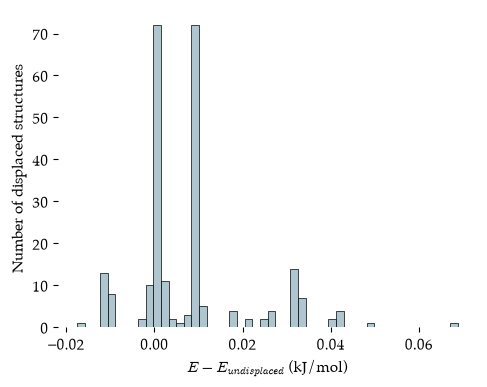

In [14]:
with open("sn2_water_freq.out") as f:
    lines = f.readlines()

energies = [float(line.split()[-1]) for line in lines if "@RKS Final Energy" in line]
dE = (np.array(energies) - energies[0]) * psi4.constants.hartree2kJmol

print(len(energies), "energies")
print(f"Lowest:  {dE.min():.4f} kJ/mol relative to the undisplaced structure")
print(f"Highest: {dE.max():.4f} kJ/mol")

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.hist(dE, bins=50, color="#AEC6CF", edgecolor="black", linewidth=0.5)
ax.set_xlabel(r"$E - E_{undisplaced}$ (kJ/mol)")
ax.set_ylabel("Number of displaced structures")
plt.show()

| Line | Notes |
| :---- | :---- |
| `[float(line.split()[-1]) for line in lines if "@RKS Final Energy" in line]` | The final energy of every structure in the Hessian calculation. The first one is the undisplaced structure, the rest are the small displacements. |
| `(np.array(energies) - energies[0]) * psi4.constants.hartree2kJmol` | Each energy relative to the undisplaced structure, in kJ/mol. |
| `ax.hist(dE, bins=50, ...)` | A **histogram**: how many displaced structures fall in each small range of energy. |

The displacements are tiny (0.005 Bohr), so the energies should all lie in one narrow cluster around zero. In my first run with the coarse grid, a second cluster sat about 0.75 kJ/mol below the rest: the grid jumps. [[Is there still a second cluster? Spread of the energies.]]

| Line | Notes |
| :---- | :---- |
| `dertype="energy"` | Build the Hessian from **energies** only. Without it, *Psi4* would use gradients that leave out the solvent (see the box near the top of the notebook). |

[[How long the water Hessian took; number of displacements (search the .out for the findif summary); imaginary frequency in water vs gas; any small imaginary or near-zero modes from noise.]]

### Why We Stop Here: Derivatives in Water

In *GAMESS*, the next steps were a **saddle point** search and an **IRC** in water. I tried the same thing in *Psi4* three times, and three times it failed. The boxes near the top of this notebook tell the story: first the *PCMSolver* cavity, then the missing solvent forces, then the grid that swings round our symmetric molecule. Each fix helped, but the Hessian above still has an impossible imaginary frequency beside the real one, and the energies of the displaced structures still fall on separate levels instead of changing smoothly. So why did *GAMESS* manage it?

**What *GAMESS* does** (according to its documentation):

- It calculates the gradient of the PCM energy **analytically**, from formulas, including how the solvent charges change when the atoms move (the `$PCMGRD` group). Every step of my *GAMESS* optimization, saddle point search and IRC used exact forces.
- Its default way of cutting the cavity into tiles, FIXPVA ("fixed points with variable area"), "gives smooth potential surfaces during geometry optimizations". The tiles are fixed to each atom's sphere and shrink or grow smoothly instead of appearing and vanishing.
- Its Hessian with solvent, `METHOD=SEMINUM` (the method *GAMESS* told me to use), "does numerical differentiation of analytically computed first derivatives". It takes differences of **exact gradients**, never of energies.

**What *Psi4* has to do:**

- Neither of its solvent libraries has gradients, so every force must come from **differences between energies**. A gradient divides a tiny energy difference by a tiny step (0.005 Bohr), which magnifies any small jump in the energy about a **hundred** times. A Hessian built from energies takes differences of differences, which magnifies a jump about **forty thousand** times. That is how jumps of 0.0003 Hartree turned into vibrations of 22000i cm<sup>&minus;1</sup>.
- The energies have tiny jumps in them: first from the *PCMSolver* tiles, then from the *ddX* grid swinging round our symmetric molecule. They are harmless in a single energy, which is why our single point in water always looked sensible, but not in the differences between nearby energies.
- A finer grid shrinks the jumps, but each water energy then builds a large grid in memory. A Hessian needs a few hundred energies and an IRC in water thousands, and my computer **ran out of memory** twice.

So the difference is not that *GAMESS* has the better solvent model. *GAMESS* differentiates its solvent model with formulas, and *Psi4* has to do it with numbers, and numbers magnify every little bump. In fairness, *GAMESS* was not flawless either. My optimization in water fell off the saddle point, and the saddle point that it did find was about 0.2&nbsp;% away from *D<sub>3h</sub>* (C&ndash;Cl 2.3912 and 2.3907 &Aring;). Its documentation even warns that the tiles "amount to a finite grid (so the PCM energy is not strictly rotationally invariant)". Exact gradients could cope with that roughness. Energy differences cannot.

### The Plan: Water Energies Along the Gas Phase Path

So we will use *Psi4*'s solvent model only for what it does well: **single energies**.

1. Follow the **IRC in gas phase**, where *Psi4* has exact gradients.
2. Calculate the **energy in water** at every point along that path.

For the transition state itself, we keep the gas phase structure. By symmetry, the transition state in water must also be *D<sub>3h</sub>*, and *GAMESS* found its C&ndash;Cl bonds only 0.007 &Aring; longer in water than in gas phase.

```{note}
This is **not** the same thing as the IRC in water that I ran with *GAMESS*. Our path is the gas phase path, and we only ask how water changes the energy of the **same** structures. In water, the real path would let the structures relax as the chloride leaves. In particular, the gas phase IRC stops where the chloride is still stuck to the methyl chloride, so our path will not follow the chloride as it drifts off into the water. We will compare our energies with the *GAMESS* IRC in water in the [third notebook](103-IRCPlots.ipynb).
```

-----

## Running the IRC

We have an **optimized saddle point** in gas phase. Let us follow it downhill in both directions. As in *GAMESS*, I will **not use symmetry** for the IRC. Our `c1_copy()` function takes care of that.

In *GAMESS*, the recipe looked like this, with each input file run **twice**, changing `FORWRD=.TRUE.` to `FORWRD=.FALSE.` to run the other direction.

1. Take a previous input file
2. Swap out the coordinates
3. Add a `$PCM` group if needed
4. Swap out the `$HESS` group

```text
 $IRC PACE=GS2 OPTTOL=0.0001 MXOPT=300 STRIDE=0.30
      SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.TRUE. NPOINT=300 $END
```

In *Psi4*, it is a few options, as in the [Diels-Alder chapter](../09-DielsAlder/091-DielsAlder.ipynb).

| *GAMESS* `$IRC` | *Psi4* option | Meaning |
| :---- | :---- | :---- |
| `RUNTYP=IRC` | `"opt_type": "irc"` | Follow the reaction path. |
| `PACE=GS2` | (the only method) | The Gonzalez-Schlegel second order method. Each step moves a fixed distance along the path and then does a small **constrained optimization** on a sphere around the new point. *Psi4*'s optimizer uses the same method. |
| `FORWRD=.TRUE.` / `.FALSE.` | `"irc_direction": "forward"` / `"backward"` | Which way to leave the saddle point. Which direction is called "forward" is meaningless. We run **two jobs**. |
| `STRIDE=0.30` | `"irc_step_size": 0.3` | The distance between points on the path in **mass-weighted** coordinates (amu<sup>&frac12;</sup> bohr). |
| `NPOINT=300` | `"irc_points": 20` | The **most** points to calculate. Both programs stop early if they reach a minimum. 20 points of 0.3 is 6 amu<sup>&frac12;</sup> bohr in each direction, farther than *GAMESS* went. |
| `SADDLE=.TRUE.` + `$HESS` | (automatic) | *Psi4* calculates the **Hessian** at the transition state itself at the start of an IRC. It cannot reuse one from an earlier job the way I pasted the `$HESS` group into *GAMESS*. The optimizer has an option to read a Hessian from a file (`hessian_file`), but when *Psi4* drives the optimizer, *Psi4* calculates a fresh Hessian whenever the optimizer asks for one, file or no file. |

```{note}
*GAMESS* printed an IRC point about every 0.1 amu<sup>&frac12;</sup> bohr in my log files, so our *Psi4* path will have fewer, more widely spaced points than the *GAMESS* one. The shape should be the same.
```

```{admonition} Two changes after the first run
The first time I ran this notebook, the IRC calculations did not behave. I dug into the source code of *Psi4*'s optimizer, *optking*, to find out why, and made two changes to the `run_irc()` function below.

**1. Cartesian coordinates for the IRC: `"opt_coordinates": "cartesian"`**

- *The problem.* Both gas phase IRCs **quit after only 6 points** (1.8 amu<sup>&frac12;</sup> bohr) with the message "One of the bends keeps passing through 180 degrees". The path had not reached a minimum.
- *Why it happened.* The optimizer normally works in **internal coordinates**: bond lengths, bond angles and dihedral angles. Any angle above about 175&deg; is treated as a special "linear bend". Our Cl&ndash;C&ndash;Cl angle starts at exactly 180&deg;, and as the umbrella of hydrogens flips, the optimizer's description of that angle swings back and forth **through** 180&deg;. *optking* contains a safety check: if a point on the path needs more than 6 small optimization steps and any angle has passed through 180&deg; more than 3 times, it assumes it is going round in circles and stops.
- *The fix and why it might work.* With `"opt_coordinates": "cartesian"` the optimizer uses the plain *x*, *y*, *z* coordinates of the atoms. There are no angles at all, so there is no angle to pass through 180&deg; and nothing to trip the safety check. The IRC is defined in (mass-weighted) Cartesian coordinates anyway, so nothing is lost. In the [Diels-Alder chapter](../09-DielsAlder/091-DielsAlder.ipynb), Cartesian coordinates made the IRC worse, but there the trouble was different, and our molecule has only six atoms.
- *What I expect.* Both gas phase IRCs should now run until they reach the bottom of the valley, or the 20-point limit, instead of stopping at 6 points.

**2. Letting the optimizer choose its own step limit (no more `"geom_maxiter": 200`)**

- *The problem.* I had set `geom_maxiter` to 200, thinking that I was raising the limit on the total number of optimization steps from the usual 50.
- *Why it was wrong.* The *optking* source code shows that, for an IRC, the default limit is already **15 steps per point**: 15 &times; 20 = 300 steps for our 20 points. By setting 200 I had actually **lowered** the limit, and a long IRC could have been cut off.
- *The fix and what I expect.* We simply leave `geom_maxiter` out, so the optimizer uses its own IRC default. Nothing changes unless an IRC needs more than 200 steps, and then it will no longer be stopped early.

One thing the source code also told me: the optimizer gives up if a **single** point on the path needs more than 50 small steps ("Exceeded 50 iterations for a single IRC point"). My first water IRC, with *PCMSolver*, had just taken its 50th step on the very first point when the computer ran out of memory, so it was going to fail either way. The cause was the noisy solvent energies (see the boxes near the top of this notebook, and the section above on why we stopped taking derivatives in water).
```

In [15]:
def run_irc(ts_mol, direction):
    psi4.core.clean()
    psi4.core.clean_options()
    psi4.set_options({"scf_type": "pk",
                      "opt_type": "irc",
                      "irc_direction": direction,
                      "irc_step_size": 0.3,
                      "irc_points": 20,
                      "opt_coordinates": "cartesian"})

    mol = c1_copy(ts_mol)
    new_output(f"sn2_gas_irc_{direction}.out")
    E = psi4.optimize("b3lyp/3-21g", molecule=mol)

    for f in Path(".").glob("irc_traj.*.xyz"):
        f.rename(f"sn2_gas_irc_{direction}.xyz")
    return E, mol

E_gas_f, mol_gas_f = run_irc(sn2, "forward")
E_gas_b, mol_gas_b = run_irc(sn2, "backward")

print(f"Forward end:  {E_gas_f:.8f} Hartree   C3-Cl1 {bond_length(mol_gas_f, 0, 2):.4f}   C3-Cl2 {bond_length(mol_gas_f, 1, 2):.4f}")
print(f"Backward end: {E_gas_b:.8f} Hartree   C3-Cl1 {bond_length(mol_gas_b, 0, 2):.4f}   C3-Cl2 {bond_length(mol_gas_b, 1, 2):.4f}")

KeyboardInterrupt: 

| Line | Notes |
| :---- | :---- |
| `def run_irc(ts_mol, direction):` | Our function takes a transition state and a direction, `"forward"` or `"backward"`. |
| `"opt_coordinates": "cartesian"` | Let the optimizer work with the *x*, *y*, *z* coordinates of the atoms instead of bond lengths and angles. See the box above for why. |
| `mol = c1_copy(ts_mol)` | A copy of the transition state with **no symmetry**, so both runs start from the same place. |
| `Path(".").glob("irc_traj.*.xyz")` | *Psi4* writes each point of the path to a file named `irc_traj.` + a number + `.xyz`. We find it&hellip; |
| `f.rename(...)` | &hellip;and **rename** it, for example to `sn2_gas_irc_forward.xyz`, before the next run overwrites it. |

The gas phase IRCs take [[time]]. [[Number of points in each direction; did they stop early at a minimum; end energies and C–Cl distances; did the Cartesian coordinates cure the 180-degree problem?]]

Each trajectory file holds one **frame** per IRC point: the number of atoms, a title line with the step number and the energy, and one line per atom. Here is the start of one.

In [ ]:
with open("sn2_gas_irc_forward.xyz") as f:
    lines = f.readlines()
print("".join(lines[:16]))

[[Confirm title line format: `IRC trajectory step: ... E: ...`; step 0 is the transition state; coordinates in Bohr.]] As we found in the Diels-Alder chapter, the coordinates are in **Bohr**, not &Aring;ngstroms. Our `read_irc()` function converts them. These two files are the **raw data** for the [second notebook](102-IRCData.ipynb) of this chapter.

### Energies in Water Along the Path

Now the plan. We read both trajectory files, put the backward frames in reverse order so that the path runs from one end, through the transition state, to the other end, and calculate the energy of every structure in water.

In [ ]:
import gc

forward = read_irc("sn2_gas_irc_forward.xyz")
backward = read_irc("sn2_gas_irc_backward.xyz")
gas_path = list(reversed(backward)) + forward[1:]
n_back = len(backward)
print(len(gas_path), "points on the path")

psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})
use_water()
new_output("sn2_water_path.out")

rows = []
for k, frame in enumerate(gas_path):
    atom_lines = [line for line in frame["text"].split("\n")[2:] if line.strip() != ""]
    lines = ["-1 1"] + atom_lines + ["symmetry c1", "no_reorient", "no_com"]
    mol = psi4.geometry("\n".join(lines))

    E_water = psi4.energy("b3lyp/3-21g", molecule=mol)
    rows.append({"stride": round((k - (n_back - 1)) * 0.3, 2),
                 "energy water": E_water,
                 "solvation": psi4.variable("DD SOLVATION ENERGY")})
    print(f"{rows[-1]['stride']:6.2f}   gas {frame['Energy']:.8f}   water {E_water:.8f}")

    psi4.core.clean()
    gc.collect()

water_path = pd.DataFrame(rows)
water_path.to_json("sn2_water_path_B3LYP321G.json", orient="records", indent=2)

| Line | Notes |
| :---- | :---- |
| `import gc` | The *Python* **garbage collector**, which frees memory that is no longer used. |
| `list(reversed(backward))` | The backward frames, **last first**. The path now starts at the far end of the backward run and finishes at the transition state. |
| `forward[1:]` | The forward frames without the first one, which is the transition state again. |
| `n_back = len(backward)` | The number of backward frames. The transition state is frame `n_back - 1` of the path. |
| `use_water()` | Switch the solvent on, once, for all of the energies in the loop. |
| `for k, frame in enumerate(gas_path):` | Loop over the points of the path. `k` counts them: 0, 1, 2&hellip; |
| `frame["text"].split("\n")[2:]` | The atom lines of the frame (already converted to &Aring;ngstroms by `read_irc()`). Lines 0 and 1 are the number of atoms and the title. |
| `["-1 1"] + atom_lines + ["symmetry c1", ...]` | A complete geometry: charge and multiplicity, the atoms, and no symmetry. |
| `round((k - (n_back - 1)) * 0.3, 2)` | The **stride**, the distance along the path: negative on the backward side, zero at the transition state, positive on the forward side. |
| `psi4.variable("DD SOLVATION ENERGY")` | The solvent's part of the energy, saved for later. |
| `gc.collect()` | Throw away the solvent grid of the last calculation before the next one is built. |
| `water_path.to_json(...)` | Saves the water energies as `sn2_water_path_B3LYP321G.json`. The [second notebook](102-IRCData.ipynb) joins them to the gas phase path. |

This cell takes [[time]]: [[number]] single energies and no derivatives. [[Compare gas and water energies along the path: is the transition state still the highest point in water? How far down are the ends in water vs gas?]]

-----

## Interpretation of IRC Results

In the *GAMESS* book, I loaded the `.log` file for one of the IRC results into *MacMolPlt*, **appended** frames using the second file that used the **reverse** direction, **annotated** the bond lengths and **exported** an animated GIF. We already have the frames in order in `gas_path`. Let us play them with *py3Dmol*.

In [ ]:
gas_movie = show_movie(gas_path)
with open("sn2_gas_irc.xyz", "w") as f:
    f.write(gas_movie)

| Line | Notes |
| :---- | :---- |
| `show_movie(gas_path)` | Plays the frames of the path and returns them as one multi-frame *xyz* text. |
| `with open("sn2_gas_irc.xyz", "w")` | Saves the movie. You can open it in *Avogadro* and play it with the animation tool. |

The **gas phase** reaction. [[Describe the movie.]]

In *GAMESS*, the C&ndash;Cl bond length at the end of the **solvent** IRC was much longer than at the end of the gas phase IRC. In the "products", the gas phase profile kept the chloride closer and the C&ndash;Cl bond was longer. The energy minimum was also much higher than in the solvent case (don't trust the values with these low level methods, but the relative magnitudes are instructive). Our path is the gas phase path in both cases, so we can only compare the **energies**. [[Gas vs water energies at the ends of our path.]]

In gas phase, the lowest energy **complex** is actually slightly along the reaction coordinate to the transition state. Chloride anion in a **vacuum** is very high in energy and **pushing** electron density into the back of the methyl chloride results in a charge-transfer complex with some of the negative charge now being **shared** on the chloride of the methyl chloride. Sharing the charge lowers the energy even though bonds are "starting" to change. Gas phase is an **extreme** environment and charged species will be **very high** in energy here.

### The Ground State

What is the calculated C&ndash;Cl **bond length** in the methyl chloride starting material? In *GAMESS*, all I needed to do was **change** the point group in the transition state input file from *D<sub>3h</sub>* to *C<sub>3v</sub>*, and the charge to zero. In *Psi4*, we leave out the second chloride. We will start with the same flat CH<sub>3</sub> group and let the optimizer bend it into a pyramid.

In [ ]:
lines = ["0 1"]
lines.append(f"Cl 0.0 0.0 {r_CCl}")
lines.append("C 0.0 0.0 0.0")
for angle in [0, 120, 240]:
    theta = np.radians(angle)
    lines.append(f"H {r_CH * np.cos(theta):.6f} {r_CH * np.sin(theta):.6f} 0.0")

ch3cl = psi4.geometry("\n".join(lines))

psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})

new_output("ch3cl_gas_opt.out")
E_ch3cl_gas = psi4.optimize("b3lyp/3-21g", molecule=ch3cl)

print(f"Final energy: {E_ch3cl_gas:.8f} Hartree")
print("Point group: ", ch3cl.get_full_point_group())
print(f"C-Cl    {bond_length(ch3cl, 0, 1):.4f} Angstrom")
print(f"C-H     {bond_length(ch3cl, 1, 2):.4f} Angstrom")
print(f"Cl-C-H  {bond_angle(ch3cl, 0, 1, 2):.2f} degrees")

| Line | Notes |
| :---- | :---- |
| `lines = ["0 1"]` | Methyl chloride is **neutral**. |
| `f"Cl 0.0 0.0 {r_CCl}"` | Only **one** chloride this time. With nothing below the carbon, the molecule is *C<sub>3v</sub>*. |
| `bond_angle(ch3cl, 0, 1, 2)` | The Cl&ndash;C&ndash;H angle. It starts at 90&deg; (flat CH<sub>3</sub>). |

[[CH3Cl gas: C–Cl, C–H, angle, point group, steps.]] *GAMESS* found the same C&ndash;Cl bond length, 1.92&nbsp;&Aring;, in gas phase and in water, so for the same reasons as above we do not optimize methyl chloride in water. We just calculate its energy in water at the gas phase structure.

In [ ]:
ch3cl_water = c1_copy(ch3cl)

psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})
use_water()

new_output("ch3cl_water_sp.out")
E_ch3cl_water = psi4.energy("b3lyp/3-21g", molecule=ch3cl_water)

print(f"Gas phase:  {E_ch3cl_gas:.8f} Hartree")
print(f"Water:      {E_ch3cl_water:.8f} Hartree")
print(f"Difference: {(E_ch3cl_water - E_ch3cl_gas) * psi4.constants.hartree2kJmol:.2f} kJ/mol")

[[Solvation energy of neutral CH3Cl vs the anionic transition state.]] A neutral molecule is stabilized much **less** by water than the negatively charged transition state.

Now let us put the methyl chloride C&ndash;Cl bond beside the two C&ndash;Cl distances at the **ends** of the IRC, and save everything we have calculated in a JSON file.

In [ ]:
def path_end(frame):
    xyz = frame["xyz"]
    return {"C3-Cl1": np.linalg.norm(xyz[0] - xyz[2]),
            "C3-Cl2": np.linalg.norm(xyz[1] - xyz[2])}

rows = [
    {"Structure": "TS", "E gas": E_ts_gas, "E water": E_sp_water,
     "C3-Cl1": bond_length(sn2, 0, 2), "C3-Cl2": bond_length(sn2, 1, 2)},
    {"Structure": "IRC first point", "E gas": gas_path[0]["Energy"],
     "E water": water_path["energy water"].iloc[0], **path_end(gas_path[0])},
    {"Structure": "IRC last point", "E gas": gas_path[-1]["Energy"],
     "E water": water_path["energy water"].iloc[-1], **path_end(gas_path[-1])},
    {"Structure": "CH3Cl", "E gas": E_ch3cl_gas, "E water": E_ch3cl_water,
     "C3-Cl1": bond_length(ch3cl, 0, 1), "C3-Cl2": np.nan},
]

summary = pd.DataFrame(rows)
summary.to_json("sn2_summary_B3LYP321G.json", orient="records", indent=2)
summary.round(4)

| Line | Notes |
| :---- | :---- |
| `def path_end(frame):` | A small function that measures the two C&ndash;Cl distances of one IRC frame. Rows 0, 1 and 2 of the coordinates are Cl1, Cl2 and C3. |
| `**path_end(gas_path[0])` | The `**` **unpacks** the dictionary returned by `path_end()` into the row, as if we had typed its two entries by hand. `gas_path[0]` is the first frame of the path and `gas_path[-1]` the last. |
| `water_path["energy water"].iloc[0]` | The water energy of the first point of the path. `.iloc[-1]` is the last. |
| `np.nan` | "Not a number", an empty cell. Methyl chloride has only one C&ndash;Cl bond. |
| `summary.to_json(...)` | Saves the table as `sn2_summary_B3LYP321G.json`. |

In *GAMESS*, the calculated C&ndash;Cl bond in methyl chloride **in solvent** was 1.92&nbsp;&angst;. The solvent IRC settled down to a ground state with the two C&ndash;Cl distances being 1.96&nbsp;&angst; and 3.11&nbsp;&angst;. This is very much like a chloride and a methyl chloride. **In water**, the chloride ion is much **more stable** on its own and is able to relax to a fully non-bonding distance. Our gas phase path cannot show that, because it stops where the gas phase IRC stops.

In **gas-phase**, the *GAMESS* C&ndash;Cl length in methyl chloride was 1.92&nbsp;&angst;. In the IRC, the ground state was reached with C&ndash;Cl lengths of 2.10&nbsp;&angst; and 2.73&nbsp;&angst;. We have a bond that is significantly **longer** than the covalent C&ndash;Cl distance for methyl chloride and the other is significantly **shorter** than a non-bonded distance. [[Psi4 numbers: CH3Cl gas vs gas IRC ends.]]

### Conclusion

We can conclude that the solvent model made a **large difference**. This fact will be made even more obvious if we visualize the data by plotting it.

-----

## Plotting Results

The first thing that I need is a **table** of the two C&ndash;Cl bond lengths and the gas phase and water energies for each point on the IRC path. In *GAMESS*, the `.log` file was enormous and I used *grep* to pull out the lines with the path distance, the energy and the two C&ndash;Cl stretches into eight little text files. Here we already have the two trajectory files, one frame per point, with the gas phase energy in the title line and the coordinates of every atom, plus the water energies in `sn2_water_path_B3LYP321G.json`.

I could have done the rest of the work in this notebook, but I will do it in two more *Jupyter* notebooks so that all of the work is **documented** step by step. If there is a mistake, the stepwise code in the notebook can be examined.

- In the [second notebook](102-IRCData.ipynb) we **clean and collate** the data and save the tables for future use.
- In the [third notebook](103-IRCPlots.ipynb) we import the tables and **plot** the IRC energies, a More O'Ferrall&ndash;Jencks plot and a 3-D plot.

-----

## Summary

Adding the **solvent model** made a huge difference in the energy of the reaction. The IRC for *S<sub>N</sub>2* was familiar to us when modelled in **water** but was not when modelled in **gas phase**.

In the **solvent model**, the system moves to lower energy as the chloride **leaves** into the pool of mathematical water. We can easily imagine **separate** chloride and methyl chloride that meet and react. [[Check against the water energies along our path.]]

In **gas phase**, the chloride is not stabilized and is high in energy when it is alone. To relax its electron density it is actually the lowest energy state to have a **partial bond** to the carbon of methyl chloride and, consequently, to have the C&ndash;Cl bond in methyl chloride **partially broken**. This is a state that we would consider to be "on the way" to reacting and not a ground state. But we are familiar with solvent reactions, not gas phase.

These are the operations that we have performed over the course of this activity.

1.	**Build** the *D<sub>3h</sub>* transition state from three unique positions, and **optimize** it in gas phase, where symmetry holds it on the saddle point.
2.	**Evaluate the vibrations** and find the **imaginary vibration** that points along the reaction coordinate.
3.	**Switch on** the water solvent model, calculate the solvation energy and the Hessian in water, and find out why derivatives with a continuum solvent are so hard in *Psi4*.
4.	**Follow the IRC** downhill in both directions in gas phase, **make a movie** of the reaction, and calculate the energy in **water** at every point along the path.
5.	**Optimize** methyl chloride in gas phase, calculate its energy in water, and compare it with the ends of the IRC.

**Gas phase is not the same as solvent**. Should we redo everything that we did up until now by switching on the PCM options and running the calculations again? That will be left as an exercise for the reader.

-----

## A Challenge

### The Activity

Is the rotational energy profile of **butane** different in water and cyclohexane solvents compared to gas phase? My hypothesis is that there will be little difference.

Is the rotational energy profile of **butadiene** different in water and cyclohexane solvents compared to gas phase? My hypothesis is that there will be a detectable, but not large difference. We do have large changes in electronic structure as the &pi; system changes with rotation but no charges are involved.

Is the IRC of the **Diels-Alder** reaction different in water and cyclohexane solvents compared to gas phase? I think this would respond similarly to the butadiene rotation for the same reasons. But we could be surprised. Go try it.

Modify the butane rotational energy profile by using **ethylene glycol**. Does the energy at different torsional values change between water, cyclohexane and gas phase?

Modify the butadiene rotational energy profile by using **glyoxal**. Does the energy at different torsional values change between water, cyclohexane and gas phase?

Are the energies (eigenvalues) and coefficients (eigenvectors) of **molecular orbitals** different when solvent is applied? Model **butadiene** in the *s-trans* conformer and see. Then do the same with **acrolein**.

```{admonition} Hints
:class: dropdown
- To change the solvent, make a copy of `use_water()` with a different `"ddx_solvent"`, for example `"cyclohexane"`, and call it `use_cyclohexane()`.
- Every solvent calculation must be run without symmetry. Use `c1_copy()` on your molecule first, or add `symmetry c1` to the geometry.
- Remember what happened in this chapter: optimizations with the solvent model need gradients, which *Psi4* must build from many energies, and those can be unreliable. The safe approach is the one we used here: a set of **single point** energies in solvent at the structures from your gas phase scan. (The molecules in these challenges are not symmetric tops, so you could also try an optimization in solvent with `dertype="energy"` and see how it behaves.)
- Compare the orbital energies with the `orbital_table()` idea from the [benzene chapter](../07-Benzene/071-Benzene.ipynb), or simply print `wfn.epsilon_a().to_array()` for each calculation.
```

### The Report

Write a short report for one of the questions above. Show a plot comparing gas phase with at least one solvent, give the relative energies in kJ/mol, and say whether my hypothesis survived.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Solvent" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About [[a third]] of the text is **my own work**, carried over word for word or lightly edited, including the introduction to solvent models, the setup of the *D<sub>3h</sub>* transition state, the discussion of symmetry and the imaginary vibration, the interpretation of the IRC results, the summary and the challenges. The figures are also mine, from the previous book. The **rest of the page** was written by an **LLM system** at my request. I asked it to translate the *GAMESS* input files, the `$PCM` group and the *MacMolPlt* steps into *Psi4* and *Python*. The first version ran the transition state search and the IRC in water as well. When my runs failed in water, the LLM diagnosed each failure from the output files and the *Psi4* and *optking* source code, made the fixes described in the boxes (switching from *PCMSolver* to *ddX*, `dertype="energy"`, finer grids, Cartesian coordinates for the IRC), and finally replaced the water transition state search and water IRC with water energies along the gas phase path. The *Python* code, the line-by-line explanations of it, the comparisons of the *GAMESS* and *Psi4* options, the analysis of the output and the new commentary were written by the LLM. The calculations were run by me on my own computer, and the numbers quoted in the text come from those calculations.
```

In [ ]:
help(psi4.set_output_file)
